In [1]:
# ================================================================
# HEAVY BACKPACK PROJECT — ENVIRONMENT + NO-RL BASELINE
#
# What this does:
#   1. Installs prebuilt packages (no source compilation).
#   2. Creates Walker2d-v5 with its standard reward and physics.
#   3. Provides make_env(torso_mass_scale=...) for future RL.
#   4. Runs a simple scripted stepping controller.
#   5. Displays and saves a video, including falls and resets.
#
# No neural network, pretrained policy, or RL training is used.
# ================================================================

import os
import sys
import math
import time
import subprocess
import ctypes.util

started = time.time()

# Set this BEFORE importing MuJoCo or OpenGL.
# OSMesa software rendering is Linux-only (e.g. Colab CPU runtimes);
# macOS renders through GLFW and needs no extra system libraries.
IS_LINUX = sys.platform.startswith("linux")
if IS_LINUX:
    os.environ["MUJOCO_GL"] = "osmesa"
    os.environ["PYOPENGL_PLATFORM"] = "osmesa"
else:
    os.environ["MUJOCO_GL"] = "glfw"

print("1/4 Installing Python packages...")
subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--quiet", "--only-binary=:all:",
        "gymnasium[mujoco]>=1.2,<2",
        "mujoco>=3.3,<4",
        "imageio", "imageio-ffmpeg", "pillow"
    ],
    check=True
)

if IS_LINUX and not ctypes.util.find_library("OSMesa"):
    print("Installing the software-rendering library...")
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(
        ["apt-get", "install", "-y", "-qq", "libosmesa6", "libgl1"],
        check=True
    )

import numpy as np
import gymnasium as gym
import mujoco
import imageio.v2 as imageio
from PIL import Image, ImageDraw
from IPython.display import display, Video

print(f"Gymnasium {gym.__version__} | MuJoCo {mujoco.__version__}")


# ----------------------------------------------------------------
# ENVIRONMENT FACTORY
#
# This is the main function you will reuse for DDPG / TD3 / SAC.
#
# make_env()                      -> normal torso
# make_env(torso_mass_scale=1.5)  -> torso is 50% heavier
# make_env(torso_mass_scale=2.0)  -> torso mass is doubled
#
# This scales the torso's mass AND rotational inertia together,
# representing a denser torso of unchanged shape.
# It does not model an offset backpack or shift the center of mass.
# A doubled torso mass does NOT double the whole robot's mass.
# ----------------------------------------------------------------

class FixedTorsoMass(gym.Wrapper):
    def __init__(self, env, torso_mass_scale=1.0):
        super().__init__(env)

        scale = float(torso_mass_scale)
        if not np.isfinite(scale) or scale <= 0:
            raise ValueError("torso_mass_scale must be finite and positive.")

        raw = env.unwrapped
        model = raw.model

        torso_id = mujoco.mj_name2id(
            model, mujoco.mjtObj.mjOBJ_BODY, "torso"
        )
        if torso_id < 0:
            raise RuntimeError("Could not find the torso body.")

        self.torso_mass_scale = scale
        self.original_torso_mass = float(model.body_mass[torso_id])
        self.original_total_mass = float(model.body_mass.sum())

        if scale != 1.0:
            model.body_mass[torso_id] *= scale
            model.body_inertia[torso_id] *= scale

            # Recompute quantities derived from the physical parameters.
            # The caller resets the environment before taking any steps.
            mujoco.mj_setConst(model, raw.data)

        self.current_torso_mass = float(model.body_mass[torso_id])
        self.current_total_mass = float(model.body_mass.sum())


def make_env(torso_mass_scale=1.0, render_mode=None):
    base = gym.make(
        "Walker2d-v5",
        render_mode=render_mode,
        width=800,
        height=480,
        max_episode_steps=1000,
    )

    try:
        return FixedTorsoMass(base, torso_mass_scale)
    except Exception:
        base.close()
        raise


# ----------------------------------------------------------------
# SCRIPTED CONTROLLER — NO LEARNING
#
# Alternating joint-angle targets create stepping attempts.
# A proportional-derivative (PD) controller converts angle errors
# into motor commands. These gains are illustrative, not optimized.
#
# Importantly:
#   - We never set the robot's position directly.
#   - We never hold it upright artificially.
#   - Falls end an episode using the standard environment rules.
#
# Later replace this function with your learned actor.
# ----------------------------------------------------------------

def scripted_action(observation, elapsed_seconds):
    # Default observation:
    # [height, torso_angle, six joint angles,
    #  x_velocity, z_velocity, torso_angular_velocity,
    #  six joint velocities]

    joint_angles = observation[2:8]
    joint_velocities = observation[11:17]

    phase = 2.0 * np.pi * 0.85 * elapsed_seconds
    left_phase = phase + np.pi

    def leg_targets(p):
        return [
            0.25 * np.sin(p),                  # hip
            -0.20 - 0.30 * max(0.0, np.sin(p)), # knee bends on swing
            0.10 * np.sin(p + 0.4),            # ankle
        ]

    targets = np.array(
        leg_targets(phase) + leg_targets(left_phase),
        dtype=np.float64
    )

    # Actions are normalized motor controls in [-1, 1].
    kp = np.array([1.0, 1.3, 0.6, 1.0, 1.3, 0.6])
    kd = np.array([0.08, 0.08, 0.04, 0.08, 0.08, 0.04])

    action = kp * (targets - joint_angles) - kd * joint_velocities
    return np.clip(action, -1.0, 1.0).astype(np.float32)


# ----------------------------------------------------------------
# BUILD AND INSPECT THE BASELINE
# ----------------------------------------------------------------

print("\n2/4 Creating the normal-mass environment...")

# Keep at 1.0 for the initial baseline.
DEMO_TORSO_MASS_SCALE = 1.0

env = make_env(
    torso_mass_scale=DEMO_TORSO_MASS_SCALE,
    render_mode="rgb_array"
)

obs, info = env.reset(seed=42)
env.action_space.seed(42)

print("Observation space:", env.observation_space)
print("Action space:     ", env.action_space)
print(f"Torso mass: {env.current_torso_mass:.3f} kg")
print(f"Total mass: {env.current_total_mass:.3f} kg")
print(f"Physics time per action: {env.unwrapped.dt:.3f} seconds")
print("Reward: unchanged Walker2d reward.")
print("Controller: scripted joint targets + PD feedback; no RL.")


# ----------------------------------------------------------------
# RECORD A SHORT DEMO
#
# Reset after an unhealthy termination and show that reset openly.
# Record every few simulation steps to reduce rendering time.
# ----------------------------------------------------------------

print("\n3/4 Running the scripted baseline and recording video...")

OUTPUT_VIDEO = "/content/walker_no_rl_baseline.mp4"
if not os.path.isdir("/content"):
    OUTPUT_VIDEO = os.path.abspath("walker_no_rl_baseline.mp4")

SIMULATION_SECONDS = 10.0
RECORD_EVERY = 4

dt = float(env.unwrapped.dt)
fps = 1.0 / (RECORD_EVERY * dt)
total_steps = math.ceil(SIMULATION_SECONDS / dt)

episode_number = 1
episode_steps = 0
episode_return = 0.0
episode_start_x = float(env.unwrapped.data.qpos[0])
completed_episodes = []


def annotated_frame(frame, label, episode, seconds):
    picture = Image.fromarray(frame)
    draw = ImageDraw.Draw(picture)
    draw.rectangle((0, 0, picture.width, 76), fill=(22, 26, 34))
    draw.text(
        (14, 10),
        "NO RL | Scripted stepping controller",
        fill="white"
    )
    draw.text(
        (14, 31),
        f"Torso mass x{DEMO_TORSO_MASS_SCALE:.2f} | "
        f"Episode {episode} | Episode time {seconds:.2f}s",
        fill=(190, 220, 255)
    )
    draw.text((14, 52), label, fill=(255, 220, 140))
    return np.asarray(picture)


try:
    with imageio.get_writer(
        OUTPUT_VIDEO,
        fps=fps,
        codec="libx264",
        quality=7,
        macro_block_size=16,
    ) as writer:

        writer.append_data(
            annotated_frame(env.render(), "Episode start",
                            episode_number, 0.0)
        )

        for step in range(total_steps):
            action = scripted_action(obs, episode_steps * dt)

            obs, reward, terminated, truncated, info = env.step(action)

            episode_steps += 1
            episode_return += float(reward)

            ended = terminated or truncated

            if step % RECORD_EVERY == 0 or ended:
                label = (
                    "Unhealthy: episode ended; resetting"
                    if terminated else
                    "Time limit: episode ended; resetting"
                    if truncated else
                    "Real physics: balance is not guaranteed"
                )

                frame = annotated_frame(
                    env.render(),
                    label,
                    episode_number,
                    episode_steps * dt
                )
                writer.append_data(frame)

                # Briefly hold the ending so failures are visible.
                if ended:
                    for _ in range(max(1, round(fps * 0.35))):
                        writer.append_data(frame)

            if ended:
                completed_episodes.append({
                    "episode": episode_number,
                    "seconds": episode_steps * dt,
                    "distance_m": (
                        float(env.unwrapped.data.qpos[0])
                        - episode_start_x
                    ),
                    "return": episode_return,
                    "ended_unhealthy": bool(terminated),
                })

                episode_number += 1
                obs, info = env.reset(seed=42 + episode_number)
                episode_steps = 0
                episode_return = 0.0
                episode_start_x = float(env.unwrapped.data.qpos[0])

finally:
    env.close()


# ----------------------------------------------------------------
# DISPLAY RESULTS
# ----------------------------------------------------------------

print("\n4/4 Done.")
print(f"Video saved to: {OUTPUT_VIDEO}")
print(f"Completed episodes: {len(completed_episodes)}")

for result in completed_episodes[:8]:
    print(
        f"Episode {result['episode']:2d}: "
        f"{result['seconds']:.2f}s | "
        f"displacement {result['distance_m']:+.2f}m | "
        f"return {result['return']:.1f} | "
        f"unhealthy={result['ended_unhealthy']}"
    )

if len(completed_episodes) > 8:
    print(f"... plus {len(completed_episodes) - 8} additional episodes.")

print(
    "\nThis is a setup baseline. Falling here does not indicate "
    "a broken environment or tell us how an RL algorithm will perform."
)
print(
    "For later training: training_env = make_env(render_mode=None)\n"
    "For later payload testing: "
    "test_env = make_env(torso_mass_scale=1.5, render_mode='rgb_array')"
)
print(f"Cell elapsed time: {time.time() - started:.1f} seconds")

display(Video(OUTPUT_VIDEO, embed=True))

1/4 Installing Python packages...
Gymnasium 1.4.0 | MuJoCo 3.17.0

2/4 Creating the normal-mass environment...
Observation space: Box(-inf, inf, (17,), float64)
Action space:      Box(-1.0, 1.0, (6,), float32)
Torso mass: 3.665 kg
Total mass: 23.677 kg
Physics time per action: 0.008 seconds
Reward: unchanged Walker2d reward.
Controller: scripted joint targets + PD feedback; no RL.

3/4 Running the scripted baseline and recording video...

4/4 Done.
Video saved to: /Users/raghav/Documents/bipedal/walker_no_rl_baseline.mp4
Completed episodes: 8
Episode  1: 1.22s | displacement -0.97m | return 31.3 | unhealthy=True
Episode  2: 1.25s | displacement -0.97m | return 34.0 | unhealthy=True
Episode  3: 1.23s | displacement -0.96m | return 32.5 | unhealthy=True
Episode  4: 1.22s | displacement -0.96m | return 32.1 | unhealthy=True
Episode  5: 1.24s | displacement -0.98m | return 31.9 | unhealthy=True
Episode  6: 1.23s | displacement -0.96m | return 32.4 | unhealthy=True
Episode  7: 1.22s | displ

In [3]:
import numpy as np
import torch
import torch.nn as nn
import random
from copy import deepcopy

torch.set_num_threads(1)
torch.manual_seed(0)
np.random.seed(0)
random.seed(0)
env = make_env(render_mode = None)
obs, info = env.reset(seed = 0)
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.shape[0]
max_action = float(env.action_space.high[0])

In [ ]:
LOG_STD_MIN, LOG_STD_MAX = -20, 2
class GaussianActor(nn.Module):
    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(state_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
        )
        self.mean_head = nn.Linear(256, action_dim)
        self.log_std_head = nn.Linear(256, action_dim)

    def forward(self, state):
        features = self.body(state)
        return torch.tanh(self.mean_head(features))

    def sample(self, state):
        features = self.body(state)
        mean = self.mean_head(features)
        log_std = self.log_std_head(features).clamp(LOG_STD_MIN, LOG_STD_MAX)
        std = log_std.exp()
        normal = torch.distributions.Normal(mean, std)
        raw_action = normal.rsample()
        action = torch.tanh(raw_action)
        log_prob = normal.log_prob(raw_action)
        log_prob = normal.log_prob(raw_action)
        log_prob -= torch.log(1-action**2 + 1e-6)
        log_prob = log_prob.sum(dim = -1, keepdim = True)
        return action, log_prob

actor = GaussianActor(state_dim, action_dim)
state = torch.tensor(obs, dtype = torch.float32)
with torch.no_grad():
    action = actor(state)
    sampled_action, log_prob = actor.sample(state)
print("Actor output:", action)
print("Sampled action:", sampled_action)
print("Log prob:", log_prob)

Actor output: tensor([-0.0592,  0.0165, -0.0787,  0.0772, -0.0529, -0.1103])
Sampled action: tensor([-0.8662, -0.2005,  0.4634,  0.1557,  0.9321,  0.3691])
Log prob: tensor([-3.8807])


In [10]:
class Critic(nn.Module):
  def __init__(self, state_dim, action_dim):
    super().__init__()
    self.network = nn.Sequential(
        nn.Linear(state_dim + action_dim, 256),
        nn.ReLU(),
        nn.Linear(256, 256),
        nn.ReLU(),
        nn.Linear(256, 1)
    )

  def forward(self, state, action):
    combined = torch.cat([state, action], dim = -1)
    return self.network(combined)

critic = Critic(state_dim, action_dim)
with torch.no_grad():
  q_value = critic(state, action)
print("Critic output:", q_value)
print("Output shape:", q_value.shape)
assert q_value.shape == (1,)
assert torch.isfinite(q_value).all()

Critic output: tensor([-0.1087])
Output shape: torch.Size([1])


In [11]:
#build replay buffer
import random
from collections import deque
random.seed(0)
class ReplayBuffer:
  def __init__(self, capacity):
    self.capacity = capacity
    self.buffer = [] #faster indexing than deque here
    self.position = 0

  def add(self, state, action, reward, next_state, terminated):
      transition = (state.copy(), action.copy(), reward, next_state.copy(), terminated)
      if len(self.buffer) < self.capacity:
          self.buffer.append(transition)
      else:
          self.buffer[self.position] = transition
          self.position = (self.position + 1) % self.capacity

  def sample(self, batch_size):
    batch = random.sample(self.buffer, batch_size)
    states, actions, rewards, next_states, terminated = zip(*batch)
    states = torch.tensor(np.array(states), dtype = torch.float32)
    actions = torch.tensor(np.array(actions), dtype = torch.float32)
    rewards = torch.tensor(rewards, dtype = torch.float32).reshape(-1, 1)
    next_states = torch.tensor(np.array(next_states), dtype = torch.float32)
    terminated = torch.tensor(terminated, dtype = torch.float32).reshape(-1, 1)
    return states, actions, rewards, next_states, terminated
  def __len__(self):
    return len(self.buffer)

In [12]:
actor = GaussianActor(state_dim, action_dim)
critic_1 = Critic(state_dim, action_dim)
critic_2 = Critic(state_dim, action_dim)
target_critic_1 = deepcopy(critic_1)
target_critic_2 = deepcopy(critic_2)
for target in (target_critic_1, target_critic_2):
    target.requires_grad_(False)

In [13]:
gamma = 0.99
tau = 0.005
batch_size = 256
target_entropy = -float(action_dim)
log_alpha = torch.zeros(1, requires_grad = True)
replay_buffer = ReplayBuffer(capacity = 1_000_000)
actor_optimizer = torch.optim.AdamW(actor.parameters(), lr = 3e-4)
critic_optimizer = torch.optim.AdamW(
    list(critic_1.parameters()) + list(critic_2.parameters()),
    lr = 3e-4,
)
alpha_optimizer = torch.optim.AdamW([log_alpha], lr = 3e-4)

In [14]:
def soft_update(target, source):
    with torch.no_grad():
        for target_parameter, parameter in zip(target.parameters(), source.parameters()):
            target_parameter.mul_(1-tau)
            target_parameter.add_(tau * parameter)

def update_sac():
    states, actions, rewards, next_states, terminated = replay_buffer.sample(batch_size)
    alpha = log_alpha.exp().detach()
    with torch.no_grad():
        next_actions, next_log_probs = actor.sample(next_states)
        target_q1 = target_critic_1(next_states, next_actions)
        target_q2 = target_critic_2(next_states, next_actions)
        next_values = torch.min(target_q1, target_q2) - alpha * next_log_probs
        targets = rewards + gamma * (1 - terminated) * next_values
    
    q1 = critic_1(states, actions)
    q2 = critic_2(states, actions)
    critic_loss = ((q1 - targets) ** 2).mean() + ((q2 - targets) ** 2).mean()
    critic_optimizer.zero_grad()
    critic_loss.backward()
    critic_optimizer.step()
    critic_parameters = list(critic_1.parameters()) + list(critic_2.parameters())
    for parameter in critic_parameters:
        parameter.requires_grad = False
    new_actions, log_provs = actor.sample(states)
    q_new = torch.min(critic_1(states, new_actions), critic_2(states, new_actions))
    actor_loss = (alpha * log_prob - q_new).mean()
    actor_optimizer.zero_grad()
    actor_loss.backward()
    actor_optimizer.step()
    for parameter in critic_parameters:
        parameter.requires_grad = True
    alpha_loss = -(log_alpha * (log_prob.detach() + target_entropy)).mean()
    alpha_optimizer.zero_grad()
    alpha_loss.backward()
    alpha_optimizer.step()
    
    soft_update(target_critic_1, critic_1)
    soft_update(target_critic_2, critic_2)
    return critic_loss.item(), actor_loss.item(), alpha.item()

In [15]:
import time
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

total_steps = 600_000
warmup_steps = 25_000
eval_every = 10_000
eval_episodes = 5

eval_env = make_env(torso_mass_scale=1.0, render_mode=None)


def evaluate_policy(n_episodes=eval_episodes):
    returns = []
    for i in range(n_episodes):
        o, _ = eval_env.reset(seed=10_000 + i)
        done, total = False, 0.0
        while not done:
            with torch.no_grad():
                a = actor(torch.as_tensor(o, dtype=torch.float32)).numpy()
            o, r, term, trunc, _ = eval_env.step(a)
            total += r
            done = term or trunc
        returns.append(total)
    return float(np.mean(returns)), float(np.std(returns))


def moving_average(values, window=20):
    values = np.asarray(values, dtype=np.float64)
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode="valid")


def plot_progress(final=False):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

    ax1.plot(train_episode_steps, train_episode_returns, color="tab:blue", alpha=0.25, label="Training episode")
    if len(train_episode_returns) >= 20:
        ax1.plot(train_episode_steps[19:], moving_average(train_episode_returns), color="tab:blue", label="Training (20-episode avg)")
    if eval_steps:
        means, stds = np.array(eval_means), np.array(eval_stds)
        ax1.plot(eval_steps, means, color="tab:orange", marker="o", markersize=3, label="Evaluation (no noise)")
        ax1.fill_between(eval_steps, means - stds, means + stds, color="tab:orange", alpha=0.2)
    ax1.axvline(warmup_steps, color="gray", linestyle=":", label="End of random warmup")
    ax1.set_xlabel("Environment steps")
    ax1.set_ylabel("Episode return")
    ax1.set_title("SAC on Walker2d-v5: return")
    ax1.grid(alpha=0.3)
    ax1.legend(loc="upper left")

    ax2.plot(loss_steps, critic_losses, color="tab:red", label="Critic loss")
    ax2.set_yscale("log")
    ax2.set_xlabel("Environment steps")
    ax2.set_ylabel("Critic loss (log)", color="tab:red")
    ax2b = ax2.twinx()
    ax2b.plot(loss_steps, actor_losses, color="tab:green", label="Actor loss")
    ax2b.set_ylabel("Actor loss", color="tab:green")
    ax2.set_title("Losses")
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    if final:
        fig.savefig("sac_convergence.png", dpi=150)
    display(fig)
    plt.close(fig)

Step 600,000/600,000 | 30.7 min | 326 steps/s | eval 4002 ± 57 | best 4141 | alpha 0.000


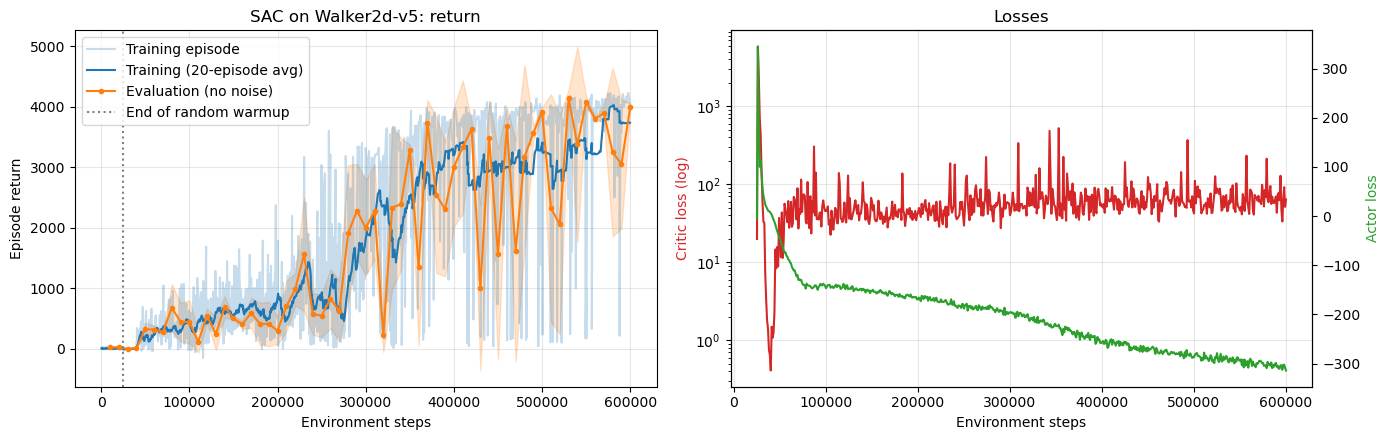

Restored best actor (eval return 4141).


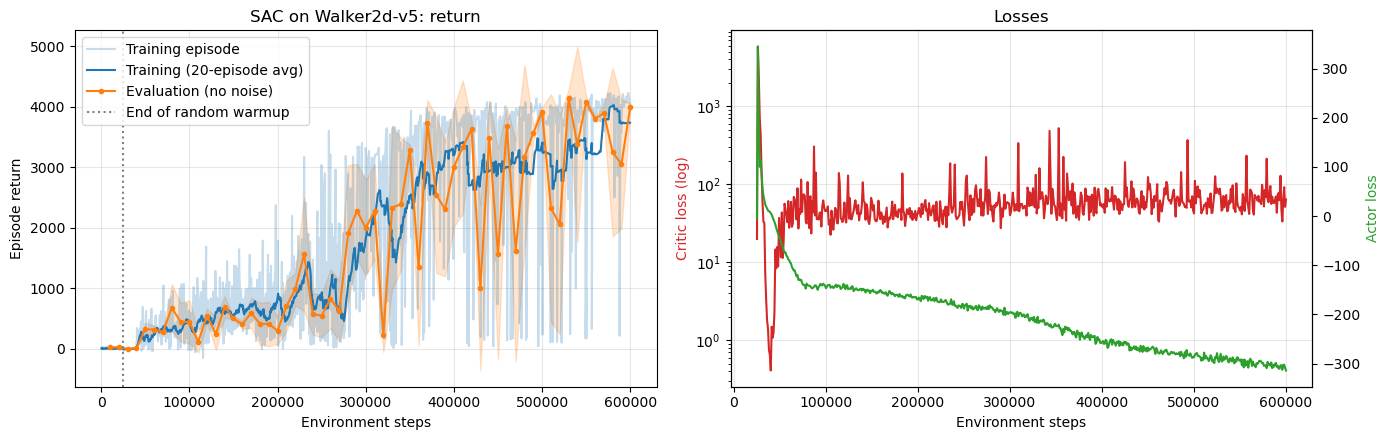

In [16]:
train_episode_steps, train_episode_returns = [], []
eval_steps, eval_means, eval_stds = [], [], []
loss_steps, critic_losses, actor_losses = [], [], []
alpha_values = []
best_eval, best_actor_state = -np.inf, None

episode_return = 0.0
obs, _ = env.reset(seed=0)
start_time = time.time()

for step in range(1, total_steps + 1):
    if len(replay_buffer) < warmup_steps:
        action = env.action_space.sample()
    else:
        with torch.no_grad():
            action, _ = actor.sample(torch.as_tensor(obs, dtype=torch.float32))
        action = action.numpy()

    next_obs, reward, terminated, truncated, _ = env.step(action)
    replay_buffer.add(obs, action, reward, next_obs, terminated)
    episode_return += reward
    obs = next_obs

    if len(replay_buffer) >= warmup_steps:
        critic_loss, actor_loss, alpha_value = update_sac()
        if step % 1_000 == 0:
            loss_steps.append(step)
            critic_losses.append(critic_loss)
            actor_losses.append(actor_loss)
            alpha_values.append(alpha_value)

    if terminated or truncated:
        train_episode_steps.append(step)
        train_episode_returns.append(episode_return)
        obs, _ = env.reset()
        episode_return = 0.0

    if step % eval_every == 0 or step == total_steps:
        mean_return, std_return = evaluate_policy()
        eval_steps.append(step)
        eval_means.append(mean_return)
        eval_stds.append(std_return)
        if mean_return > best_eval:
            best_eval = mean_return
            best_actor_state = deepcopy(actor.state_dict())

        elapsed = time.time() - start_time
        clear_output(wait=True)
        print(f"Step {step:,}/{total_steps:,} | {elapsed / 60:.1f} min | {step / elapsed:.0f} steps/s | "
              f"eval {mean_return:.0f} ± {std_return:.0f} | best {best_eval:.0f} | alpha {log_alpha.exp().item():.3f}")
        plot_progress()

eval_env.close()
actor.load_state_dict(best_actor_state)
print(f"Restored best actor (eval return {best_eval:.0f}).")
plot_progress(final=True)

In [17]:
eval_env = make_env(torso_mass_scale=1.0, render_mode=None)

try:
    for seed in range(100, 105):
        obs, _ = eval_env.reset(seed=seed)
        start_x = float(eval_env.unwrapped.data.qpos[0])
        episode_return = 0.0
        steps = 0
        terminated = truncated = False

        while not (terminated or truncated):
            state = torch.as_tensor(obs, dtype=torch.float32)
            with torch.no_grad():
                action = actor(state).numpy()

            obs, reward, terminated, truncated, _ = eval_env.step(action)
            episode_return += reward
            steps += 1

        distance = float(eval_env.unwrapped.data.qpos[0]) - start_x
        print(
            f"Seed {seed} | steps {steps} | return {episode_return:.1f} | "
            f"forward distance {distance:+.2f} m | unhealthy {terminated}"
        )
finally:
    eval_env.close()

Seed 100 | steps 1000 | return 4257.9 | forward distance +26.09 m | unhealthy False
Seed 101 | steps 1000 | return 1078.8 | forward distance +0.66 m | unhealthy False
Seed 102 | steps 1000 | return 4205.5 | forward distance +25.67 m | unhealthy False
Seed 103 | steps 1000 | return 4224.9 | forward distance +25.83 m | unhealthy False
Seed 104 | steps 1000 | return 4173.0 | forward distance +25.41 m | unhealthy False


In [19]:
import imageio.v2 as imageio  # Write rendered frames to an MP4.
from IPython.display import Video, display  # Play the video inside Colab.

seed = 100  # Choose the same starting condition as your earlier evaluation.
video_path = "sac_walker.mp4"  # Set the output filename.
video_env = make_env(torso_mass_scale=1.0, render_mode="rgb_array")  # Create a separate environment that renders images.


def follow_frame():  # Render with the camera centered on the walker.
    raw = video_env.unwrapped  # Access the MuJoCo model, data, and renderer.
    torso_x = raw.data.body("torso").xpos[0]  # The walker's current forward position.
    camera.lookat[:] = [torso_x, 0.0, 1.0]  # Follow forward motion only, so the view doesn't bob.
    return video_env.render()  # Draw the frame from the updated camera.


try:  # Close the video environment even if recording fails.
    obs, _ = video_env.reset(seed=seed)  # Start the evaluation episode.
    video_env.render()  # Create the renderer so its camera can be adjusted.
    camera = video_env.unwrapped.mujoco_renderer.viewer.cam  # The camera used for rgb_array frames.
    camera.azimuth = 90.0  # View the walker from the side.
    camera.elevation = -10.0  # Look slightly down at the floor.
    camera.distance = 4.0  # Keep the whole body in frame.
    stride = 4  # Record one frame every four physics actions.
    fps = 1 / (stride * video_env.unwrapped.dt)  # Match playback speed to simulation time.
    step = 0  # Count the actions taken in this episode.

    with imageio.get_writer(video_path, fps=fps, codec="libx264") as writer:  # Open the video file.
        writer.append_data(follow_frame())  # Record the starting pose.
        while True:  # Roll out the policy until the episode ends.
            state = torch.as_tensor(obs, dtype=torch.float32)  # Convert the observation to the actor's input format.
            with torch.no_grad():  # Turn off gradient tracking for evaluation.
                action = actor(state).numpy()  # Use the actor's motor commands directly, with no exploration noise.
            obs, _, terminated, truncated, _ = video_env.step(action)  # Apply the commands and read the next observation.
            step += 1  # Count this action.
            ended = terminated or truncated  # Check for an unhealthy state or time limit.
            if step % stride == 0 or ended:  # Capture regular frames and the final pose.
                writer.append_data(follow_frame())  # Add the current image to the video.
            if ended:  # Finish recording at the end of this episode.
                break  # Exit the rollout loop.
finally:  # Release rendering resources.
    video_env.close()  # Close the separate video environment.

print(f"Seed {seed} | {step} steps | unhealthy: {terminated}")  # Show how the recorded episode ended.
display(Video(video_path, embed=True))  # Display the playable MP4.


Seed 100 | 1000 steps | unhealthy: False


In [ ]:
import json

algo = "sac"
torch.save(actor.state_dict(), f"{algo}_actor.pt")

# Distances on seeds 100-104 at normal mass, so payload_eval.ipynb can confirm the weights reload exactly.
check_env = make_env(torso_mass_scale=1.0, render_mode=None)
reference = {}
try:
    for seed in range(100, 105):
        o, _ = check_env.reset(seed=seed)
        start_x = float(check_env.unwrapped.data.qpos[0])
        done = False
        while not done:
            with torch.no_grad():
                a = actor(torch.as_tensor(o, dtype=torch.float32)).numpy()
            o, r, term, trunc, _ = check_env.step(a)
            done = term or trunc
        reference[seed] = float(check_env.unwrapped.data.qpos[0]) - start_x
finally:
    check_env.close()

with open(f"{algo}_reference.json", "w") as f:
    json.dump(reference, f, indent=2)

print(f"Saved {algo}_actor.pt and {algo}_reference.json")
for seed, distance in reference.items():
    print(f"Seed {seed} | forward distance {distance:+.2f} m")